# Anomaly detection on bearing vibration data

NASA IMS Bearing Dataset, Set 2 (`2nd_test`): four Rexnord ZA-2115 bearings on a shaft at 2000 RPM, radial load ≈ 2700 kg,
one 1-second vibration snapshot every 10 minutes from 12/02/2004 10:32 to 19/02/2004 06:22, run to failure.

<p align="center">
  <img src="figures/test_rig.png" width="45%">
  &nbsp;&nbsp;
  <img src="figures/bearing.png" width="35%">
</p>

*Left: test rig (from the dataset README [1]), Set 1 configuration with two accelerometers per bearing; in Set 2 each bearing has one. Right: main parts of a rolling element bearing (generic schematic).*

## 0. Setup

In [224]:
import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse
from scipy import signal as sps_signal, stats as sps_stats
from sklearn.decomposition import PCA

sys.path.insert(0, str(Path.cwd().parent))          # repository root, to import src/
from src.config import BEARINGS, FEATURES, LOG_FEATURES, SAMPLING_RATE_HZ as FS
from src.features import dataset_features, transform
from src.model import alarm_intervals, fit_params as fit_model, oof_scores, persistent_alarms, score_with as score

DATA_DIR = Path("../data/2nd_test")
pd.set_option("display.width", 140)

FS

20480

## 1. The data
The file name is the acquisition timestamp, so alphabetical order is also chronological order.

In [225]:
files = sorted(DATA_DIR.iterdir())
print("Number of files:", len(files))
print("First:", files[0].name)
print("Last: ", files[-1].name)

Number of files: 984
First: 2004.02.12.10.32.39
Last:  2004.02.19.06.22.39


In [226]:
df = pd.read_csv(files[0], sep="\t", header=None, names=BEARINGS)

print("Shape:", df.shape)

df.describe()

Shape: (20480, 4)


,B1,B2,B3,B4
count,20480.000000,20480.000000,20480.000000,20480.000000
mean,-0.010196,-0.012695,-0.014541,-0.010026
std,0.073477,0.090056,0.108436,0.053168
min,-0.386000,-0.513000,-0.911000,-0.264000
25%,-0.059000,-0.073000,-0.081000,-0.046000
50%,-0.010000,-0.015000,-0.015000,-0.010000
75%,0.037000,0.046000,0.051000,0.027000
max,0.454000,0.464000,1.023000,0.193000


In [227]:
df2 = pd.read_csv(files[-1], sep="\t", header=None, names=BEARINGS)

print("Shape:", df2.shape)

df2.describe()

Shape: (20480, 4)


,B1,B2,B3,B4
count,20480.000000,20480.000000,20480.000000,20480.000000
mean,-0.001162,-0.000701,-0.000664,-0.001695
std,0.001000,0.001021,0.000996,0.001280
min,-0.005000,-0.002000,-0.005000,-0.005000
25%,-0.002000,-0.002000,-0.002000,-0.002000
50%,-0.002000,0.000000,0.000000,-0.002000
75%,0.000000,0.000000,0.000000,0.000000
max,0.002000,0.002000,0.002000,0.002000


**The last acquisitions.** The last file has a much weaker signal than the first one. This is surprising: since the test ends with an outer-race failure on B1, I would expect the last files to show more vibration, not less. To understand why, I look at the RMS (the energy of the signal) of the last six files.

,B1,B2,B3,B4
05:32,0.3870,0.1767,0.1394,0.1434
05:42,0.7250,0.2183,0.1706,0.1483
05:52,0.4620,0.1708,0.1779,0.1166
06:02,0.4838,0.1936,0.1874,0.1305
06:12,0.0010,0.0015,0.0015,0.0012
06:22,0.0010,0.0010,0.0010,0.0013


Distinct values in the last file, B1: [-0.005 -0.002  0.     0.002]


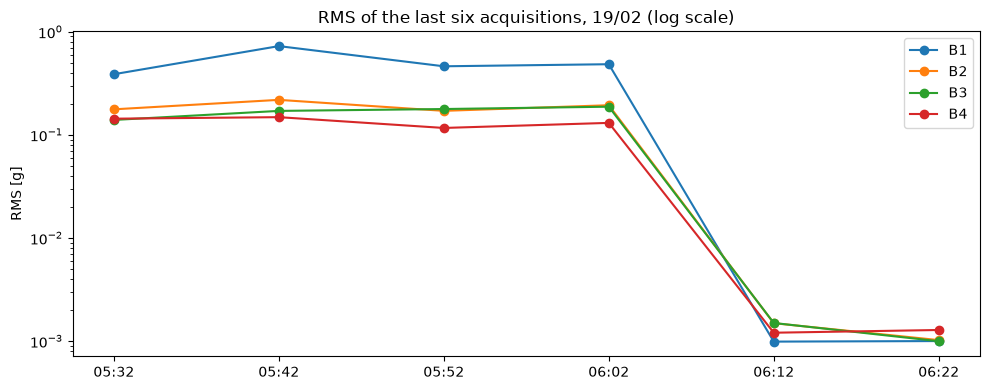

In [228]:
last = {}
for f in files[-6:]:
    x = pd.read_csv(f, sep="\t", header=None, names=BEARINGS)
    last[f.name[11:16].replace(".", ":")] = np.sqrt(((x - x.mean()) ** 2).mean())
last = pd.DataFrame(last).T
display(last.round(4))
print("Distinct values in the last file, B1:", np.unique(x["B1"]))      # x = last file of the loop

ax = last.plot(marker="o", logy=True, figsize=(10, 4), title="RMS of the last six acquisitions, 19/02 (log scale)")
ax.set_ylabel("RMS [g]")
plt.tight_layout(); plt.show()

Between 06:02 and 06:12 the RMS drops by a factor of 100 to 500 on **all four bearings at the same time**, and the last file contains only four distinct values
(−0.005, −0.002, 0 and 0.002 g): this is just the resolution of the acquisition, with no vibration left.
A possible explanation is that **the rig had already stopped**: the test was halted after the failure, or the shaft was slowing down. The dataset documentation does not say, so this remains a hypothesis.

I keep these two acquisitions in the analysis (the model flags them as anomalous), but I do not use them as examples of the faulty signal:
Section 7 uses 19/02 06:02, the last acquisition with clear vibration.

Each file holds 20,480 samples per bearing. The dataset README says 20 kHz, but 20,480 samples in 1 s means 20,480 Hz:
Section 7 confirms this value using the fault frequencies.

## 2. Representing an acquisition: time-domain features

Instead of the raw signal, each 20,480-sample channel is summarised by five standard vibration-analysis quantities.
The mean is removed first ($x \leftarrow x - \bar{x}$): it is an offset of the sensor and acquisition chain, not vibration.
Without removing it, RMS and peak would include this constant, while I want to measure only the oscillation around equilibrium.

**RMS (root mean square)**
$$\text{RMS} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} x_i^2}$$
The average vibration level, i.e. the energy of the signal. 

**Peak**
$$\text{Peak} = \max_i |x_i|$$
The largest absolute value in the second. It reacts to single impacts more than the RMS does: an isolated impact raises the maximum but barely moves the mean.

**Peak-to-peak**
$$\text{P2P} = \max_i x_i - \min_i x_i$$
The total excursion of the signal. Similar to the peak, but it takes both directions of the oscillation into account.

**Kurtosis**
$$\text{Kurt} = \frac{\frac{1}{N}\sum_{i=1}^{N} (x_i - \bar{x})^4}{\sigma^4}$$
How heavy the tails of the amplitude distribution are, i.e. how much of the signal is made of rare, strong peaks. It equals 3 for a Gaussian signal (pure noise).

**Skewness**
$$\text{Skew} = \frac{\frac{1}{N}\sum_{i=1}^{N} (x_i - \bar{x})^3}{\sigma^3}$$
Whether the signal leans towards positive or negative values; about 0 for a symmetric signal.

**In short:** RMS, peak and peak-to-peak measure **how much** the bearing vibrates; kurtosis measures **how** it vibrates (smoothly or with impacts); skewness measures asymmetry.

In [229]:
# defined in src/features.py
features = dataset_features(DATA_DIR, BEARINGS)       # one row per (acquisition, bearing)
features

,timestamp,bearing,rms,peak,p2p,kurtosis,skewness
0,2004-02-12 10:32:39,B1,0.073475,0.464196,0.840,3.628763,0.083993
1,2004-02-12 10:32:39,B2,0.090053,0.500305,0.977,3.506801,0.126915
2,2004-02-12 10:32:39,B3,0.108434,1.037541,1.934,6.213075,0.204840
3,2004-02-12 10:32:39,B4,0.053166,0.253974,0.457,3.065959,-0.022080
4,2004-02-12 10:42:39,B1,0.075338,0.385415,0.757,3.648291,0.052142
...,...,...,...,...,...,...,...
3931,2004-02-19 06:12:39,B4,0.001204,0.003786,0.007,4.652722,0.656680
3932,2004-02-19 06:22:39,B1,0.001000,0.003838,0.007,1.390226,0.317032
3933,2004-02-19 06:22:39,B2,0.001021,0.002701,0.004,1.905901,-0.250340
3934,2004-02-19 06:22:39,B3,0.000996,0.004336,0.007,1.930988,-0.395449


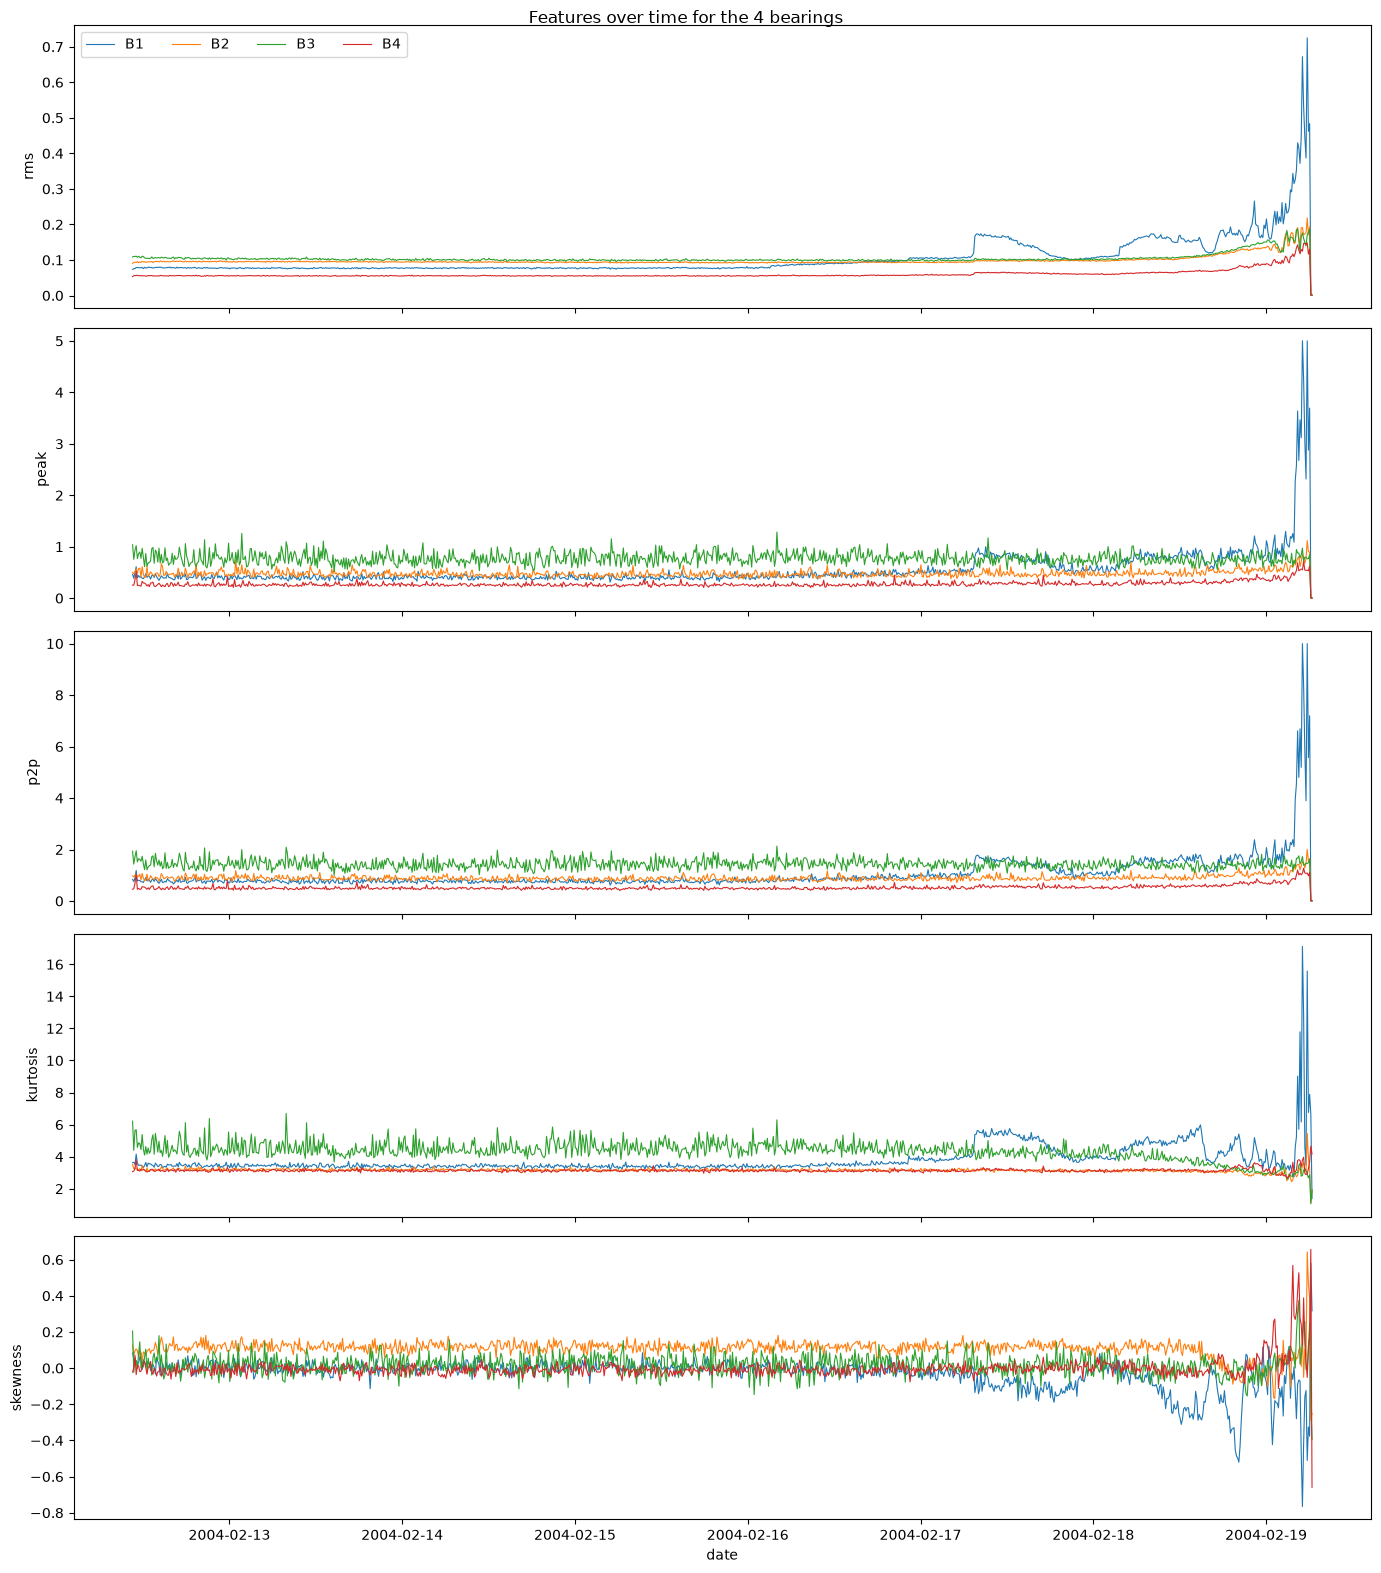

In [230]:
fig, axes = plt.subplots(len(FEATURES), 1, figsize=(14, 16), sharex=True)
for ax, feat in zip(axes, FEATURES):
    for b in BEARINGS:
        s = features[features["bearing"] == b]
        ax.plot(s["timestamp"], s[feat], linewidth=0.8, label=b)
    ax.set_ylabel(feat)
axes[0].legend(ncol=4)
axes[-1].set_xlabel("date")
fig.suptitle("Features over time for the 4 bearings")
plt.tight_layout(); plt.show()

**Preliminary analysis**

- **First 4 days (12/02 – 16/02): stable behaviour.** All five features are flat for all four bearings, apart from small fluctuations. This is what we expect from healthy bearings.
- **B1 is the first to change.** Its RMS starts to grow slowly around 16/02, then jumps on 17/02, drops and rises again on 18/02. Over the same days its kurtosis rises and its skewness becomes negative. More energy *and* more impulsive behaviour at the same time are the typical signs of a developing bearing defect.
- **B2, B3 and B4 change later and less.** Their RMS grows mainly in the last day (B4 shows a small step on 17/02, at the same time as B1's jump). Since they change later, by less and partly at the same moments as B1, the change could come from B1's vibration travelling along the shaft rather than from a defect of their own. This is checked later (Section 7).
- **Last hours: very large values on B1**, then all features of all bearings drop to almost zero in the last two files (hypothesis of rig stopped, Section 1).

## 3. Model: Mahalanobis distance

For each bearing I learn what "normal" looks like from an initial period assumed healthy, and measure how far each acquisition is from it with the Mahalanobis distance:

$$D(z) = \sqrt{z^\top \Sigma^{-1} z}$$

where $z$ is the feature vector standardised on the healthy period and $\Sigma$ its covariance matrix.

**Why this method.** No labels are available, so the detector must learn normal behaviour only. The Mahalanobis distance needs few healthy samples (here 289 per bearing for 5 features),
has no hyper-parameters to tune and has a known reference distribution under Gaussianity. It also naturally takes the correlation between features into account.

The method relies on some assumptions, which I check on the healthy period:
1. the data of each bearing form **a single compact group**, roughly elliptical: this is what makes the Mahalanobis distance meaningful;
2. the distribution is **approximately Gaussian**: only then does $D^2$ follow a chi-squared distribution, which would give a theoretical threshold.

In [231]:
HEALTHY_HOURS = 48      # initial period assumed healthy
QUANTILE = 0.995        # threshold = quantile of the healthy scores (out of sample)
PERSISTENCE = 3         # consecutive acquisitions above threshold for an alarm (30 min)

### 3.1 Data preparation
- **Healthy period**: the first 48 hours (289 acquisitions per bearing). This is enough to estimate the mean and covariance of 5 features, covers two day-night cycles and is far from the degradation.
- **Logarithm** of the positive, long-tailed features, to make their distributions more symmetric. Skewness is left unchanged because it can be negative.

In [232]:
start = features["timestamp"].min()
healthy_end = start + pd.Timedelta(hours=HEALTHY_HOURS)

data = (features
        .sort_values(["bearing", "timestamp"])
        .reset_index(drop=True))

def healthy_matrix(b, end=healthy_end, begin=start):
    df_b = data[data["bearing"] == b]
    return transform(df_b[(df_b["timestamp"] >= begin) & (df_b["timestamp"] <= end)])

for b in BEARINGS:
    print(f"{b}: {len(healthy_matrix(b))} acquisitions in the healthy period")

B1: 289 acquisitions in the healthy period
B2: 289 acquisitions in the healthy period
B3: 289 acquisitions in the healthy period
B4: 289 acquisitions in the healthy period


**Effect of the logarithm.** For each feature on the healthy period: the skewness coefficient of its distribution before and after the logarithm (0 = symmetric, positive = long right tail).

In [233]:
rows = []
for b in BEARINGS:
    h = data[(data["bearing"] == b) & (data["timestamp"] <= healthy_end)]
    for f in LOG_FEATURES:
        rows.append({"bearing": b, "feature": f,
                     "raw": sps_stats.skew(h[f]), "log": sps_stats.skew(np.log(h[f]))})
asymmetry = pd.DataFrame(rows).pivot(index="feature", columns="bearing", values=["raw", "log"]).round(2)
print("Skewness of the feature distributions, healthy period:")
display(asymmetry)

Skewness of the feature distributions, healthy period:


raw                     log                  
bearing     B1    B2    B3    B4    B1    B2    B3    B4
feature                                                 
kurtosis  1.54  0.95  1.36  3.15  1.23  0.86  1.05  2.61
p2p       1.27  0.60  0.66  3.90  0.76  0.40  0.32  2.38
peak      0.92  1.19  0.80  2.63  0.55  0.82  0.41  1.60
rms       0.01 -0.38  0.46  0.02 -0.03 -0.44  0.40 -0.02

The logarithm helps where the tail is long. For **peak** and **peak-to-peak** the skewness drops by 30–50% (B1 peak-to-peak from 1.27 to 0.76).
The **RMS** is already nearly symmetric in the healthy period (skewness between −0.4 and 0.5), so for it the logarithm changes almost nothing; I keep it anyway because it costs nothing and makes changes proportional: doubling the vibration level is the same shift whatever the starting level.
The **kurtosis** improves only a little and stays right-skewed, especially on B4 (3.15 → 2.61).

So the logarithm is a partial correction, not a full Gaussianisation. This is consistent with the heavier upper tail in the Q-Q plot (Section 3.4), and it is one reason why the threshold is taken from the data (out-of-fold quantile, Section 4) rather than from the chi-squared table.

### 3.2 Checking the assumptions

**Correlation between features.** The Mahalanobis distance accounts for the correlation between features by construction, so it makes sense to check how correlated the features actually are. Below is the Pearson correlation of the log features on the healthy period.

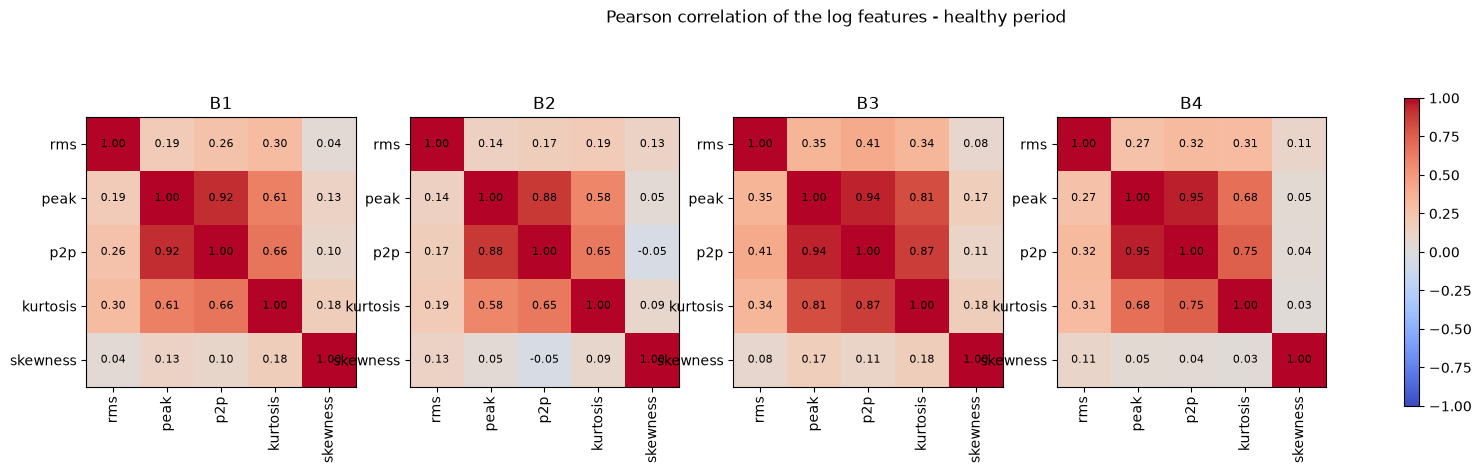

In [234]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, b in zip(axes, BEARINGS):
    corr = pd.DataFrame(healthy_matrix(b), columns=FEATURES).corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
    ax.set_yticks(range(len(FEATURES)), FEATURES)
    for i in range(len(FEATURES)):
        for j in range(len(FEATURES)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(b)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.suptitle("Pearson correlation of the log features - healthy period")
plt.show()

Some features are strongly correlated, in particular peak, peak-to-peak and kurtosis (up to 0.95).

**Shape of the healthy data.** The Mahalanobis distance assumes that normal behaviour is **a single compact, elliptical group**. I check it by projecting all 5 features onto the first two principal components (the directions along which the healthy data vary most), with the Mahalanobis ellipses at 1, 2 and 3.

In orange, the points of the whole test, to see how the anomalies leave the healthy group.

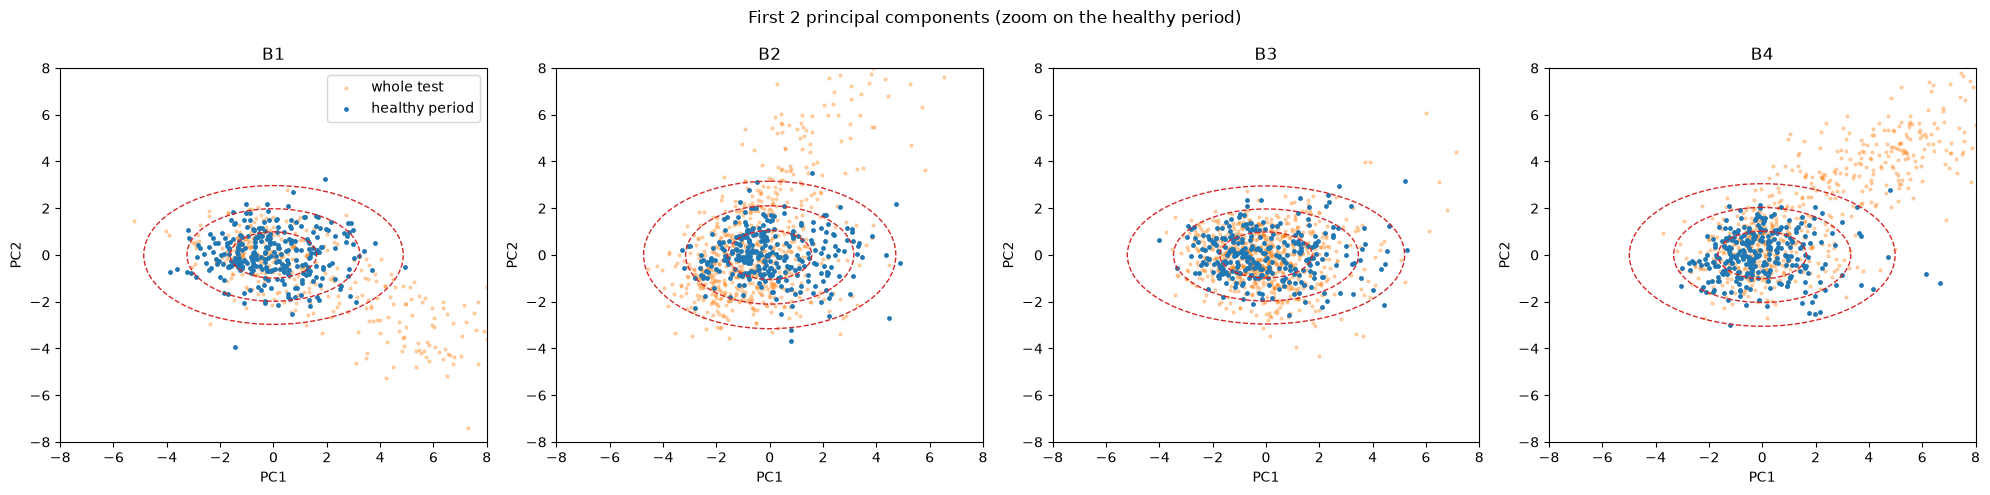

In [235]:
def draw_ellipses(ax, X, levels=(1, 2, 3)):
    mean = X.mean(axis=0)
    eigval, eigvec = np.linalg.eigh(np.cov(X, rowvar=False))
    angle = np.degrees(np.arctan2(eigvec[1, -1], eigvec[0, -1]))
    for k in levels:
        ax.add_patch(Ellipse(mean, 2 * k * np.sqrt(eigval[-1]), 2 * k * np.sqrt(eigval[0]),
                             angle=angle, fill=False, color="tab:red", linestyle="--"))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, b in zip(axes, BEARINGS):
    df_b = data[data["bearing"] == b]
    X_h = healthy_matrix(b)
    mean, std = X_h.mean(axis=0), X_h.std(axis=0)
    pca = PCA(n_components=2).fit((X_h - mean) / std)
    P_h = pca.transform((X_h - mean) / std)
    P_all = pca.transform((transform(df_b) - mean) / std)
    ax.scatter(P_all[:, 0], P_all[:, 1], s=4, color="tab:orange", alpha=0.3, label="whole test")
    ax.scatter(P_h[:, 0], P_h[:, 1], s=6, label="healthy period")
    draw_ellipses(ax, P_h)
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(b)
axes[0].legend()
fig.suptitle("First 2 principal components (zoom on the healthy period)")
plt.tight_layout(); plt.show()

**First two principal components.** Using all 5 features, the healthy data of each bearing form a single, roughly elliptical cloud centred at zero, with no separate subgroups: the main assumption of the Mahalanobis distance holds. Most healthy points lie within ellipse 3; the few outside are consistent with the heavier upper tail seen in the Q-Q plot (Section 3.4).

### 3.3 Fitting
For each bearing, on the healthy period:
1. standardise the features (mean and standard deviation of the healthy period);
2. estimate the covariance and invert it (precision matrix).

In [236]:
models = {}
data["score"] = np.nan
for b in BEARINGS:
    mask = data["bearing"] == b
    models[b] = fit_model(healthy_matrix(b))
    data.loc[mask, "score"] = score(transform(data[mask]), models[b])

### 3.4 Gaussianity: Q-Q plot against chi-squared
If the healthy data are Gaussian, $D^2$ follows a chi-squared distribution with as many degrees of freedom as features: **5**.
If the points follow the line, the assumption is reasonable. A deviation in the upper tail means heavier tails than Gaussian: then the threshold is better estimated from the data than from the theoretical table.

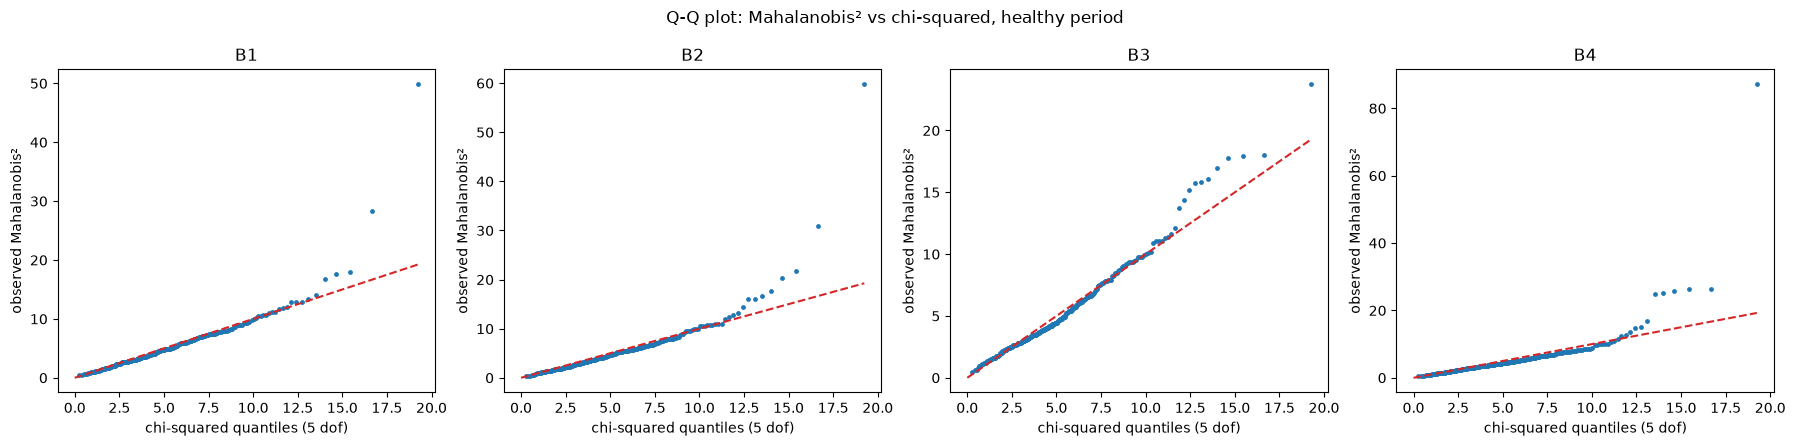

In [237]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, b in zip(axes, BEARINGS):
    s = data[(data["bearing"] == b) & (data["timestamp"] <= healthy_end)]["score"].to_numpy()
    d2 = np.sort(s ** 2)
    theo = sps_stats.chi2.ppf((np.arange(1, len(d2) + 1) - 0.5) / len(d2), df=5)
    ax.scatter(theo, d2, s=6)
    ax.plot([0, theo.max()], [0, theo.max()], color="tab:red", linestyle="--")
    ax.set_xlabel("chi-squared quantiles (5 dof)"); ax.set_ylabel("observed Mahalanobis²"); ax.set_title(b)
fig.suptitle("Q-Q plot: Mahalanobis² vs chi-squared, healthy period")
plt.tight_layout(); plt.show()

The centre of the distribution follows the chi-squared well; the upper tail is heavier. For Gaussian data the largest D² expected among 289 points is about 18:
- the most extreme healthy point of every bearing falls in the **first half hour of the test** (the run-in of the rig), and on B1, B2 and B4 it is 3 to 5 times the expected maximum (D² = 50, 60 and 87);
- apart from the run-in, the other extreme points are only slightly above the expected maximum (D² ≈ 18–31): the tails are **moderately heavier than Gaussian**.

This is why the threshold is estimated from the data (Section 4) rather than taken from the chi-squared table.

## 4. Anomaly threshold

**Threshold = 99.5% quantile of the healthy-period scores, computed out of sample:**

$$\tau_b = Q_{0.995}\left(\{ D_{\text{oof}}(x_t) : t \in H \}\right)$$

So about 1 healthy acquisition in 200 exceeds the threshold by chance.

**Why out of sample.** If they were scored by the model fitted on them, the healthy acquisitions would get optimistic scores (the model has already seen them) and the threshold would be too low. Instead:
1. the 289 healthy acquisitions are split into 5 **contiguous** blocks (58, 58, 58, 58, 57), never shuffled: neighbouring acquisitions are similar, and shuffling would put them in both training and test;
2. each block is scored with a model fitted on the other 4;
3. every healthy acquisition gets one score from a model that has not seen it.

**Why not the chi-squared table.** For Gaussian data the 99.5% quantile of $\chi^2_5$ gives $D = 4.09$, below all the thresholds found here: the healthy tail is heavier than Gaussian (Q-Q plot, Section 3.4), so the theoretical value would give too many false alarms.

In [238]:
thresholds = {}
for b in BEARINGS:
    oof = oof_scores(healthy_matrix(b))
    thresholds[b] = np.quantile(oof, QUANTILE)
    print(f"{b}: threshold = {thresholds[b]:.2f}")

B1: threshold = 5.25
B2: threshold = 5.55
B3: threshold = 4.40
B4: threshold = 5.39


## 5. Persistence rule, onset and anomalous intervals

With a 99.5% threshold, about one healthy acquisition in 200 exceeds it by chance. An alarm is therefore raised only if the score stays above the threshold for at least **3 consecutive acquisitions** (30 minutes): a real fault is persistent, noise is not. The onset is the first acquisition of the first alarm run.

In [239]:
data["alarm"] = False
onsets = {}
for b in BEARINGS:
    mask = data["bearing"] == b
    above = data.loc[mask, "score"].to_numpy() > thresholds[b]
    data.loc[mask, "alarm"] = persistent_alarms(above, PERSISTENCE)
    ts = data.loc[mask, "timestamp"].to_numpy()
    alarm = data.loc[mask, "alarm"].to_numpy()
    onsets[b] = pd.Timestamp(ts[alarm].min()) if alarm.any() else None
    display(alarm_intervals(ts, alarm).style.set_caption(f"{b}"))

,start,end,acquisitions
0,2004-02-16 03:22:39,2004-02-19 06:22:39,451


,start,end,acquisitions
0,2004-02-18 03:52:39,2004-02-18 04:12:39,3
1,2004-02-18 04:52:39,2004-02-18 05:12:39,3
2,2004-02-18 05:52:39,2004-02-18 07:32:39,11
3,2004-02-18 07:52:39,2004-02-19 06:22:39,136


,start,end,acquisitions
0,2004-02-18 14:02:39,2004-02-19 06:22:39,99


,start,end,acquisitions
0,2004-02-17 07:12:39,2004-02-18 01:32:39,111
1,2004-02-18 01:52:39,2004-02-18 02:42:39,6
2,2004-02-18 03:02:39,2004-02-19 06:22:39,165


**Score over time.** For each bearing: the score (log scale), the threshold, the alarms and the onset.

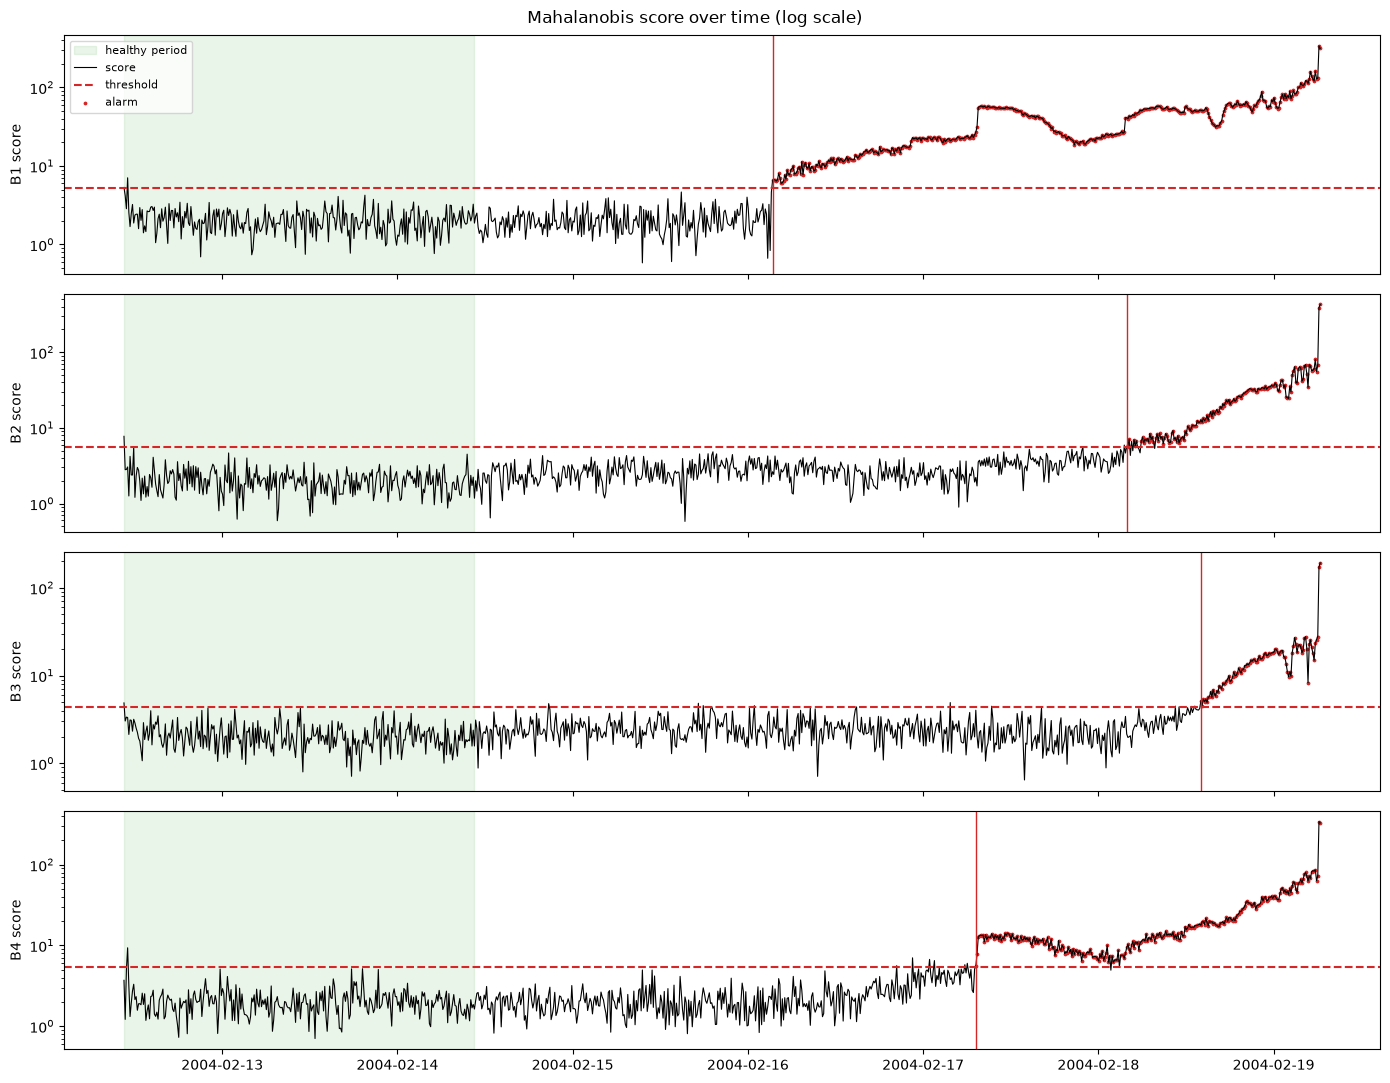

In [240]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, b in zip(axes, BEARINGS):
    s = data[data["bearing"] == b]
    ax.axvspan(s["timestamp"].min(), healthy_end, color="tab:green", alpha=0.1, label="healthy period")
    ax.plot(s["timestamp"], s["score"], color="black", linewidth=0.8, label="score")
    ax.axhline(thresholds[b], color="tab:red", linestyle="--", label="threshold")
    ax.scatter(s.loc[s["alarm"], "timestamp"], s.loc[s["alarm"], "score"], s=3, color="tab:red", label="alarm")
    if onsets[b] is not None:
        ax.axvline(onsets[b], color="tab:red", linewidth=1)
    ax.set_yscale("log"); ax.set_ylabel(f"{b} score")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Mahalanobis score over time (log scale)")
plt.tight_layout(); plt.show()

**What the score shows.**

- **Healthy until the onset; isolated peaks are filtered out.** In all four bearings the score stays between ≈ 1 and 5, also in the days after the healthy period (14/02 – 16/02) that the model has never seen. The few isolated points above the threshold (the run-in at the start, single spikes on B4 in the early hours of 17/02) do not become alarms thanks to the persistence rule.
- **B1 is the first and clearest anomaly.** It crosses the threshold on 16/02 at 03:22, never comes back below it, and grows by about two orders of magnitude in phases: a step on 17/02, a dip during 17–18/02, a new rise on 18/02.
- **The other bearings follow.** B4 jumps on 17/02 at 07:12, exactly when B1 does; B2 (18/02 03:52) and B3 (18/02 14:02) rise later and gradually. In the last two files all four scores jump above 100 only because the rig has stopped (Section 1).

**Open question.** The order B1 → B4 → B2 → B3 and the simultaneous step of B1 and B4 suggest that the later anomalies may be caused by B1's vibration rather than by new faults. Section 7 checks whether each bearing shows a fault signature of its own.

## 6. Robustness

The method has three parameters chosen by me: the length of the healthy period, the threshold quantile and the persistence. I check how much the anomaly onset depends on them, over all $3 \times 3 \times 3 = 27$ combinations.

In [241]:
HOURS_LIST, Q_LIST, K_LIST = [24, 48, 72], [0.99, 0.995, 0.999], [1, 3, 6]

def sensitivity():
    rows = []
    for hours in HOURS_LIST:
        end = start + pd.Timedelta(hours=hours)
        cache = {}
        for b in BEARINGS:
            mask = data["bearing"] == b
            X_h, X = healthy_matrix(b, end), transform(data[mask])
            cache[b] = (data.loc[mask, "timestamp"].to_numpy(), score(X, fit_model(X_h)), oof_scores(X_h))
        for q, k in itertools.product(Q_LIST, K_LIST):
            row = {"healthy hours": hours, "quantile": q, "persistence": k}
            for b, (ts, s, oof) in cache.items():
                alarm = persistent_alarms(s > np.quantile(oof, q), k)
                row[b] = pd.Timestamp(ts[alarm].min()) if alarm.any() else pd.NaT
            rows.append(row)
    return pd.DataFrame(rows)

sens = sensitivity()

robust = sens[sens["persistence"] >= 3][BEARINGS].agg(["min", "max"]).T
robust["width [h]"] = (robust["max"] - robust["min"]).dt.total_seconds() / 3600
print("Anomaly onset over 18 combinations (persistence >= 3):")
display(robust)

Anomaly onset over 18 combinations (persistence >= 3):


,min,max,width [h]
B1,2004-02-16 03:12:39,2004-02-16 07:42:39,4.500000
B2,2004-02-17 20:42:39,2004-02-18 12:52:39,16.166667
B3,2004-02-18 14:02:39,2004-02-18 15:42:39,1.666667
B4,2004-02-17 07:12:39,2004-02-17 07:32:39,0.333333


The onset of B1, B3 and B4 is stable within a few hours, and the order B1 → B4 → B2 → B3 never changes.

## 7. Physical validation a posteriori

The dataset has no labels to validate the model against. I therefore validate it a posteriori with envelope analysis, a standard technique in bearing diagnostics that does not use the model's features.

The idea: every time a rolling element passes over a defect, it produces a small impact. The impacts repeat at a frequency that depends on **where** the defect is:
- **BPFO**: defect on the outer race;
- **BPFI**: defect on the inner race;
- **BSF**: defect on a rolling element.

If the envelope spectrum shows a peak at the BPFO, the bearing probably has an outer-race defect.

### 7.1 Characteristic fault frequencies

Computed from the geometry of the Rexnord ZA-2115 reported by Qiu et al. (2006) [2]: $n = 16$ rollers per row, pitch diameter $D = 71.5$ mm, roller diameter $d = 8.4$ mm,
contact angle $\varphi = 15.17°$, shaft frequency $f_r = 2000/60 \approx 33.3$ Hz.

$$\text{BPFO} = \frac{n f_r}{2}\left(1 - \frac{d}{D}\cos\varphi\right) \qquad
\text{BPFI} = \frac{n f_r}{2}\left(1 + \frac{d}{D}\cos\varphi\right) \qquad
\text{BSF} = \frac{D f_r}{2d}\left(1 - \left(\frac{d}{D}\cos\varphi\right)^2\right)$$

In [242]:
n_rollers, D, d, phi = 16, 71.5, 8.4, np.radians(15.17)
f_r = 2000 / 60
r = d / D * np.cos(phi)

FAULT_FREQS = {
    "bpfo": n_rollers * f_r / 2 * (1 - r),
    "bpfi": n_rollers * f_r / 2 * (1 + r),
    "bsf": D * f_r / (2 * d) * (1 - r**2),
}
{k: round(float(v), 1) for k, v in FAULT_FREQS.items()}

{'bpfo': 236.4, 'bpfi': 296.9, 'bsf': 140.0}

### 7.2 Envelope spectrum

For each channel:
1. 4th-order Butterworth **high-pass filter** at 1 kHz: removes the shaft rotation and slow vibrations, and keeps the band where the impacts resonate;
2. **envelope** with the Hilbert transform: each impact becomes a "bump";
3. **FFT of the envelope**: if the bumps repeat 236 times per second, a peak appears at 236 Hz.

Below, one file at the start of the test and one at the end, for B1.
For the end I use 19/02 06:02, the last acquisition with clear vibration (Section 1).

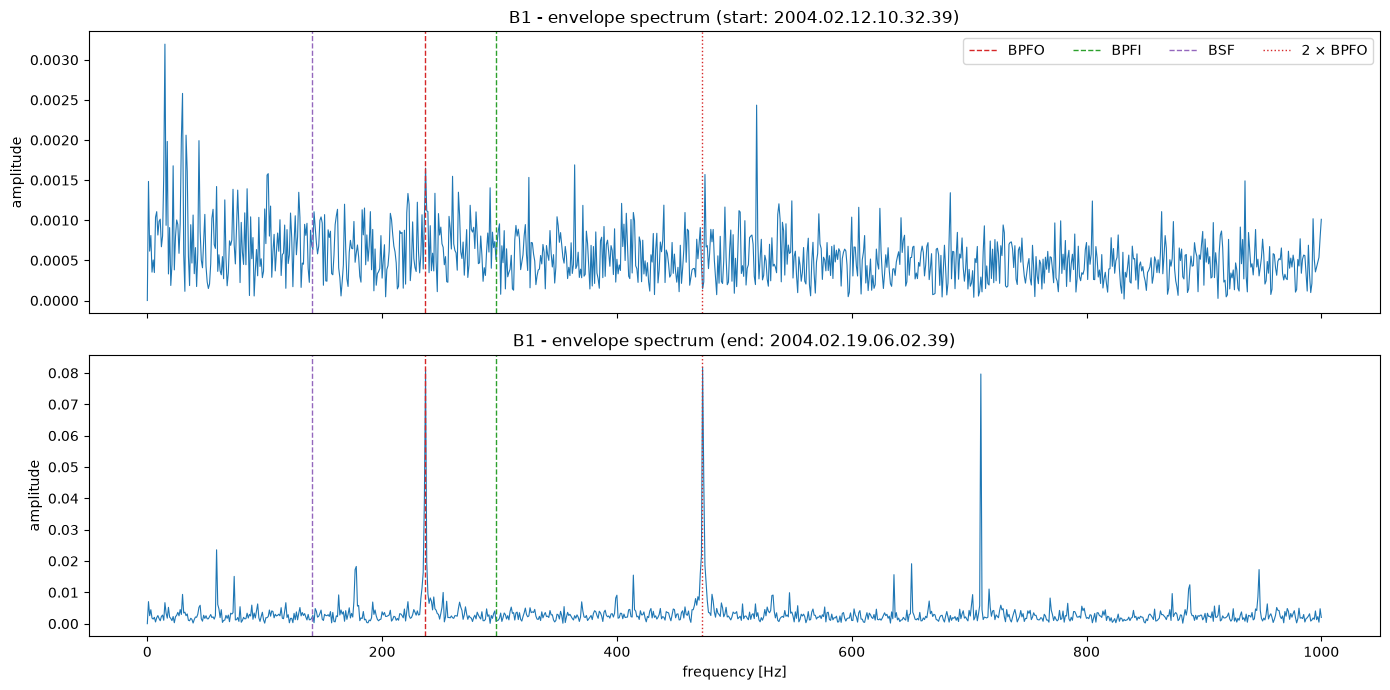

In [243]:
def envelope_spectrum(x, fs=FS, highpass=1000):
    x = x - x.mean()
    sos = sps_signal.butter(4, highpass, btype="highpass", fs=fs, output="sos")
    filtered = sps_signal.sosfiltfilt(sos, x)          # forward and backward: no phase shift
    env = np.abs(sps_signal.hilbert(filtered))
    env = env - env.mean()
    spec = np.abs(np.fft.rfft(env)) / len(env)
    freqs = np.fft.rfftfreq(len(env), 1 / fs)
    return freqs, spec

COLORS = {"bpfo": "tab:red", "bpfi": "tab:green", "bsf": "tab:purple"}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, f, label in [(axes[0], files[0], "start"), (axes[1], files[-3], "end")]:   # files[-3]: last acquisition with vibration
    x = pd.read_csv(f, sep="\t", header=None, names=BEARINGS)["B1"].to_numpy()
    freqs, spec = envelope_spectrum(x)
    sel = freqs <= 1000
    ax.plot(freqs[sel], spec[sel], linewidth=0.8)
    for name, f0 in FAULT_FREQS.items():
        ax.axvline(f0, color=COLORS[name], linestyle="--", linewidth=1, label=name.upper())
    ax.axvline(2 * FAULT_FREQS["bpfo"], color="tab:red", linestyle=":", linewidth=1, label="2 × BPFO")
    ax.set_ylabel("amplitude"); ax.set_title(f"B1 - envelope spectrum ({label}: {f.name})")
axes[0].legend(ncol=4)
axes[-1].set_xlabel("frequency [Hz]")
plt.tight_layout(); plt.show()

**Checking the sampling frequency.** If the sampling frequency were wrong, the frequency axis would be stretched and the peak would not fall on the theoretical BPFO.
I take the dominant envelope peak of B1 at the end of the test and compute its frequency under both hypotheses.

In [244]:
x = pd.read_csv(files[-3], sep="\t", header=None, names=BEARINGS)["B1"].to_numpy()
freqs, spec = envelope_spectrum(x, fs=20480)
sel = (freqs > 150) & (freqs < 350)
peak_bin = np.argmax(spec[sel]) + np.argmax(sel)        # bin index in the full spectrum

print(f"Bin of the dominant peak: {peak_bin}")
print(f"Frequency if fs = 20,000 Hz: {peak_bin * 20000 / 20480:.1f} Hz")
print(f"Frequency if fs = 20,480 Hz: {peak_bin * 20480 / 20480:.1f} Hz")
print(f"Theoretical BPFO: {FAULT_FREQS['bpfo']:.1f} Hz")

Bin of the dominant peak: 237
Frequency if fs = 20,000 Hz: 231.4 Hz
Frequency if fs = 20,480 Hz: 237.0 Hz
Theoretical BPFO: 236.4 Hz


With 20,480 Hz the peak falls at 237 Hz, 0.6 Hz from the theoretical BPFO; with 20 kHz it would be 5 Hz off. The sampling frequency is therefore 20,480 Hz.

### 7.3 Envelope indicators for all acquisitions
For every acquisition and bearing I measure how much the envelope spectrum stands out at the three fault frequencies:
the maximum within ±3 Hz of the frequency, divided by the typical level of the spectrum (median between 10 and 1000 Hz).

In [245]:
def fault_amplitude(freqs, spec, f0, half_width=3):
    baseline = np.median(spec[(freqs > 10) & (freqs < 1000)])
    return spec[np.abs(freqs - f0) <= half_width].max() / baseline

rows = []
for f in files:
    sig = pd.read_csv(f, sep="\t", header=None, names=BEARINGS)
    ts = pd.to_datetime(f.name, format="%Y.%m.%d.%H.%M.%S")
    for b in BEARINGS:
        freqs, spec = envelope_spectrum(sig[b].to_numpy())
        rows.append({"timestamp": ts, "bearing": b,
                     **{f"env_{k}": fault_amplitude(freqs, spec, f0) for k, f0 in FAULT_FREQS.items()}})

env = pd.DataFrame(rows)
data = data.merge(env, on=["timestamp", "bearing"], how="left")

### 7.4 Physical indicator vs model alarm over time
For each bearing: the indicator at the BPFO (outer race) and, as a control, those at the BPFI and BSF. The dashed line is the model's anomaly onset.

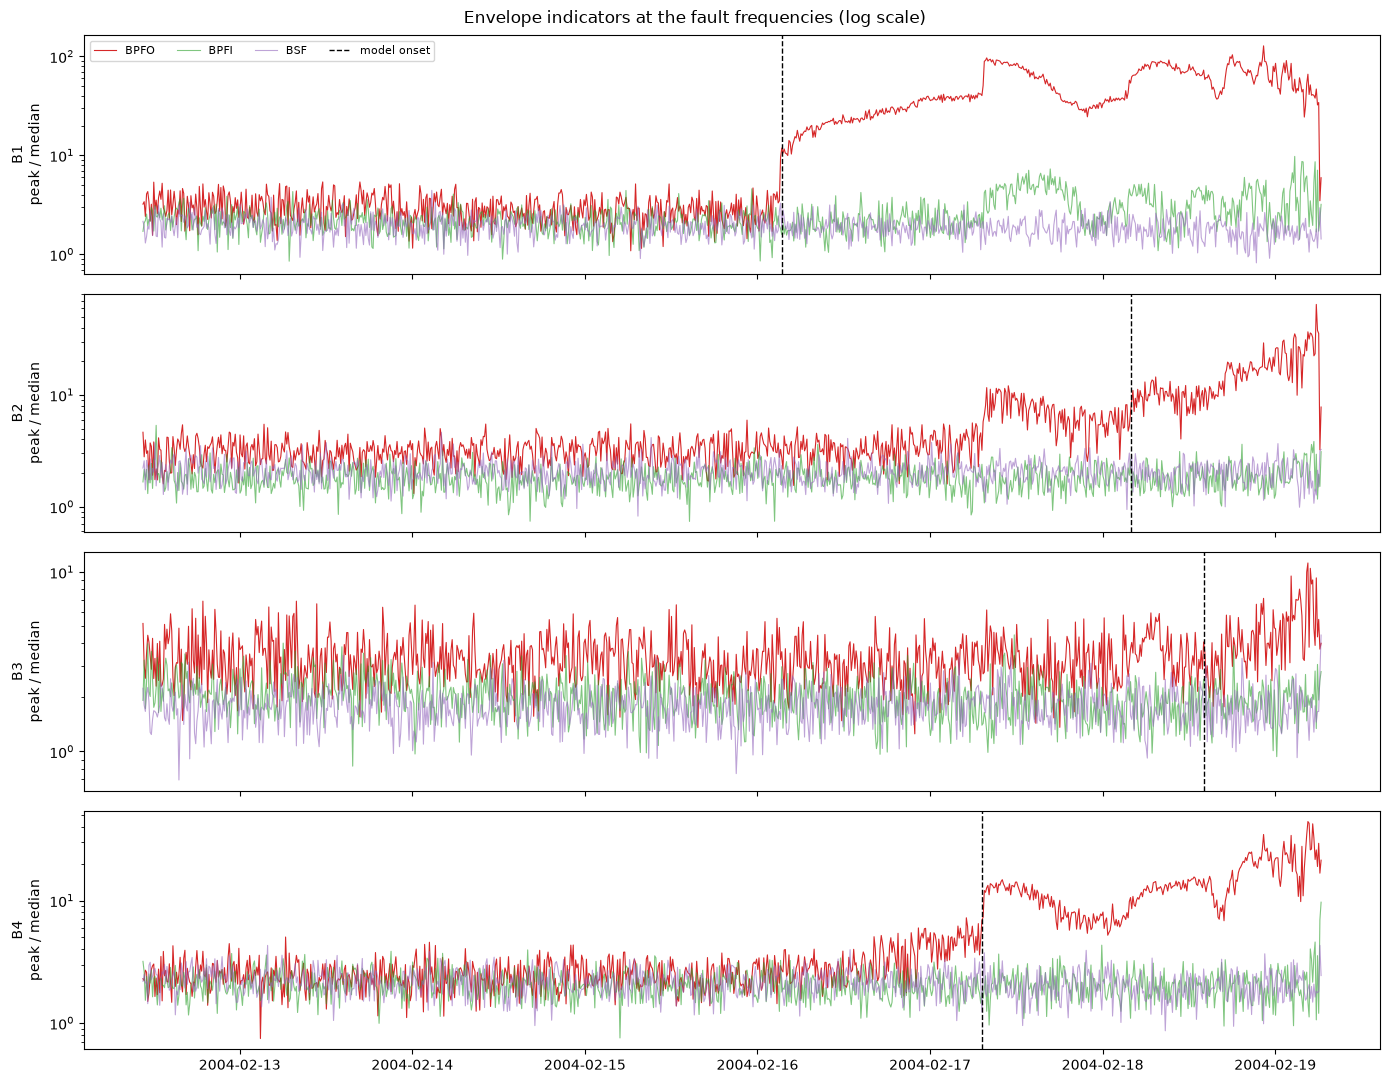

In [246]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, b in zip(axes, BEARINGS):
    s = data[data["bearing"] == b]
    for k in FAULT_FREQS:
        ax.plot(s["timestamp"], s[f"env_{k}"], linewidth=0.8, color=COLORS[k], label=k.upper(),
                alpha=1 if k == "bpfo" else 0.6)
    if onsets[b] is not None:
        ax.axvline(onsets[b], color="black", linestyle="--", linewidth=1, label="model onset")
    ax.set_yscale("log"); ax.set_ylabel(f"{b}\npeak / median")
axes[0].legend(loc="upper left", ncol=4, fontsize=8)
fig.suptitle("Envelope indicators at the fault frequencies (log scale)")
plt.tight_layout(); plt.show()

**What the plot shows.**

- **B1: a clear outer-race signature at the model onset.** Before the onsets all indicators are noise (≈ 2–5). On B1 the BPFO jumps from ≈ 3 to ≈ 10 at the model onset (16/02, 03:22) and grows up to ≈ 100, with the same phases as the score; BPFI and BSF stay an order of magnitude lower.
- **B4 and B2: the same signature, weaker; B3 almost none.** The BPFO of B4 and B2 grows with the same time pattern as B1 (the step on the morning of 17/02 appears on all three at once) but stays at ≈ 10–40, while BPFI and BSF stay flat. On B3 the BPFO rises only slightly in the last hours, after the model onset.
- **Last files.** The drop of the BPFO at the very end is the rig stopping (Section 1).

**Reading.** Only the outer-race frequency grows, it is strongest on B1, and the same pattern appears, weaker, on the other bearings: **a single outer-race defect on B1**, whose vibration travels along the shaft and reaches the other sensors. The next section compares the model onset with the onset of this signature.

### 7.5 Physical onset vs model onset
I apply to the BPFO indicator the same rule as the model: the outer-race signature is present when `env_bpfo` exceeds the 99.5% quantile of its own healthy period for at least 3 consecutive acquisitions.
For each bearing I compare when this signature appears with the model's anomaly onset.

**Locating the source.** The BPFO is the same for all four bearings, so B1's signature also reaches the other sensors along the shaft. The source is the bearing where the indicator grows **the most**. As a control, BPFI and BSF should not grow.

In [247]:
rows = []
for b in BEARINGS:
    s = data[data["bearing"] == b]
    healthy_env = s.loc[s["timestamp"] <= healthy_end, "env_bpfo"]
    phys = persistent_alarms(s["env_bpfo"].to_numpy() > healthy_env.quantile(QUANTILE), PERSISTENCE)
    phys_onset = pd.Timestamp(s["timestamp"].to_numpy()[phys].min()) if phys.any() else pd.NaT
    rows.append({
        "bearing": b,
        "model onset": onsets[b],
        "BPFO onset": phys_onset,
        "model - physical [h]": round((onsets[b] - phys_onset).total_seconds() / 3600, 1),
    })
validation = pd.DataFrame(rows).set_index("bearing")
validation

,model onset,BPFO onset,model - physical [h]
bearing,,,
B1,2004-02-16 03:22:39,2004-02-16 03:12:39,0.2
B2,2004-02-18 03:52:39,2004-02-17 07:22:39,20.5
B3,2004-02-18 14:02:39,2004-02-19 02:52:39,-12.8
B4,2004-02-17 07:12:39,2004-02-16 22:42:39,8.5


In [248]:
rows = []
for b in BEARINGS:
    s = data[data["bearing"] == b]
    healthy = s[s["timestamp"] <= healthy_end]
    after = s[s["timestamp"] >= onsets[b]]
    rows.append({"bearing": b,
                 **{f"{k.upper()} after / healthy": round(after[f"env_{k}"].median() / healthy[f"env_{k}"].median(), 2)
                    for k in FAULT_FREQS}})
diagnosis = pd.DataFrame(rows).set_index("bearing")
diagnosis

,BPFO after / healthy,BPFI after / healthy,BSF after / healthy
bearing,,,
B1,13.58,1.18,0.89
B2,4.21,0.99,0.95
B3,1.27,0.90,0.97
B4,5.30,0.99,0.88


### Interpretation
- **Timing**: on B1 the BPFO signature appears on 16/02 at 03:12 and the model fires at 03:22, 10 minutes later. Two different measures computed from the same signal, one statistical (time-domain features) and one physical (fault frequency), point to the same moment.
- **Type and source of the defect**: on B1 the BPFO indicator grows ×13.6 over the healthy period, while BPFI and BSF barely change (median ×1.18 and ×0.89; the BPFI rises at times on 17–18/02, but stays an order of magnitude below the BPFO): an **outer-race** defect.
  On B2 and B4 the BPFO grows much less (×4.2 and ×5.3) and on B3 hardly at all (×1.3): what reaches those sensors is probably B1's signature, not a defect of their own.
- **B2, B3, B4**: here the BPFO onset measures B1's fault as seen by the other sensors. 
- **Consistency with the documentation**: the dataset README reports an outer-race failure of bearing 1 at the end of the test.

## 8. Summary

**Question.** Are there anomalies? If so, in which bearings, and since when?

**Answer.** Yes. The source is **bearing B1**, anomalous from **16/02/2004 03:22**, about **3 days before the end of the test**, continuously until the end.
B4 (from 17/02 07:12), B2 (from 18/02 03:52) and B3 (from 18/02 14:02) also become anomalous later. Their alarms reflect real changes in the signal, but the evidence points to **B1's vibration transmitted along the shaft** rather than to new faults.

**Method.** Each acquisition is summarised by five time-domain features per bearing. The anomaly score is the Mahalanobis distance from the first 48 hours (assumed healthy).
The threshold is the 99.5% quantile of the out-of-fold healthy scores, and an alarm requires 3 consecutive acquisitions above it.

**Validation without labels.** I check the result a posteriori with a physical indicator that the model does not use: envelope analysis at the bearing fault frequencies.
On B1 the outer-race fault frequency (BPFO) appears **10 minutes before** the model alarm and grows ×13.6, while the inner-race and rolling-element frequencies do not change: an **outer-race fault on B1**, which also matches the dataset documentation.

## 9. Limitations and possible extensions

**Limitations**
- **One run to failure, one fault type.** The whole evaluation rests on a single test with an outer-race fault: nothing guarantees that the same thresholds or features work for other faults or other machines.
- **Independent models per bearing.** They cannot separate a faulty bearing from one that receives its vibration.

**Possible extensions**
- A joint model on the four channels.

## 10. References

[1] J. Lee, H. Qiu, G. Yu, J. Lin, and Rexnord Technical Services, "Bearing Data Set", IMS, University of Cincinnati, 2007.
NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA. Includes the *Readme Document for IMS Bearing Data*.
Downloaded from Kaggle: [kaggle.com/datasets/vinayak123tyagi/bearing-dataset](https://www.kaggle.com/datasets/vinayak123tyagi/bearing-dataset)

[2] H. Qiu, J. Lee, J. Lin, G. Yu, "Wavelet filter-based weak signature detection method and its application on rolling element bearing prognostics",
*Journal of Sound and Vibration*, 289 (2006), 1066–1090. [doi:10.1016/j.jsv.2005.03.007](https://doi.org/10.1016/j.jsv.2005.03.007)